# Networks, Tuning and Dynamics

Beyond spike trains, analyses of neural models need views of connectivity, stimulus selectivity and population dynamics. This notebook covers:

| View | Function |
|---|---|
| weight matrix | `connectivity_matrix` |
| network graph | `network_topology` |
| pairwise correlations | `correlation_matrix` |
| stimulus tuning | `tuning_curve` |
| 2-D dynamics: trajectory and vector field | `phase_portrait` |
| population trajectory in a low-dimensional space | `neural_trajectory` |

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import braintools

plt.rcParams["figure.dpi"] = 90
rng = np.random.default_rng(1)

## 2. Connectivity Matrices

A network of 40 excitatory and 10 inhibitory neurons with 20 % connection probability. Weights are stored as `W[pre, post]`: row $i$ holds the outgoing connections of neuron $i$, so a neuron's sign is constant along its row (Dale's law). `connectivity_matrix` labels rows "Pre-synaptic" and columns "Post-synaptic" accordingly, and `center_zero=True` (the default) centers the diverging colormap at zero so that excitation and inhibition get opposite colors of equal intensity.

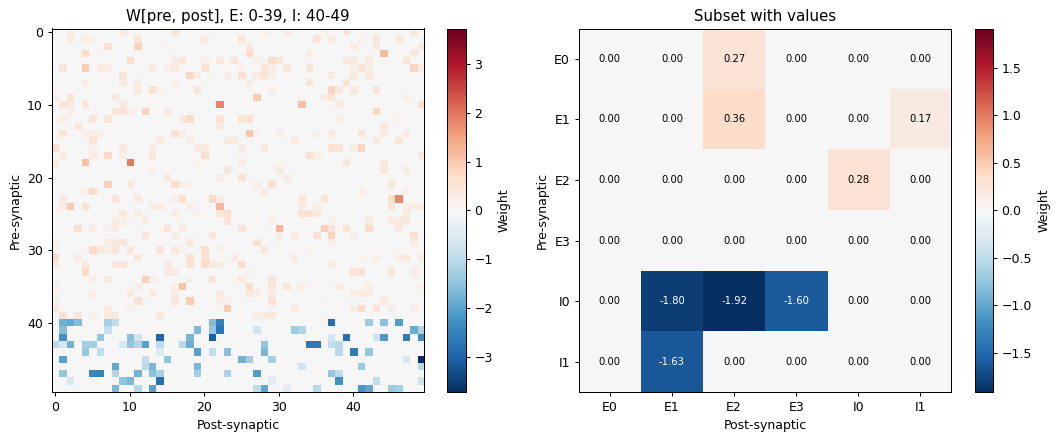

row sums of the inhibitory neurons are all negative: True


In [2]:
n_e, n_i = 40, 10
n = n_e + n_i
mask = rng.random((n, n)) < 0.2
np.fill_diagonal(mask, False)
W = mask * rng.lognormal(-1.0, 0.5, (n, n))
W[n_e:] = -4.0 * W[n_e:] + 0.0         # inhibitory rows, 4x stronger (+ 0.0 turns -0.0 into 0.0)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
braintools.visualize.connectivity_matrix(W, ax=ax[0], title="W[pre, post], E: 0-39, I: 40-49")
labels = [f"E{i}" for i in range(4)] + [f"I{i}" for i in range(2)]
sub = np.ix_([0, 1, 2, 3, 40, 41], [0, 1, 2, 3, 40, 41])
braintools.visualize.connectivity_matrix(W[sub], pre_labels=labels, post_labels=labels, show_values=True,
                                         ax=ax[1], title="Subset with values")
plt.tight_layout(); plt.show()
print("row sums of the inhibitory neurons are all negative:", bool(np.all(W[n_e:].sum(1) <= 0)))

## 3. Network Graphs

`network_topology` draws the non-zero entries of an adjacency or weight matrix as lines between nodes (direction is not shown). Without explicit `edge_colors`, positive edges are gray and negative ones blue. `edge_widths` accepts one width per edge or an `(N, N)` matrix, such as the absolute weights. Node positions come from `positions` or from a layout: `'circular'`, `'random'`, or a simple `'spring'` layout. The random layouts draw from NumPy's global generator; seed it with `np.random.seed` for reproducible figures.

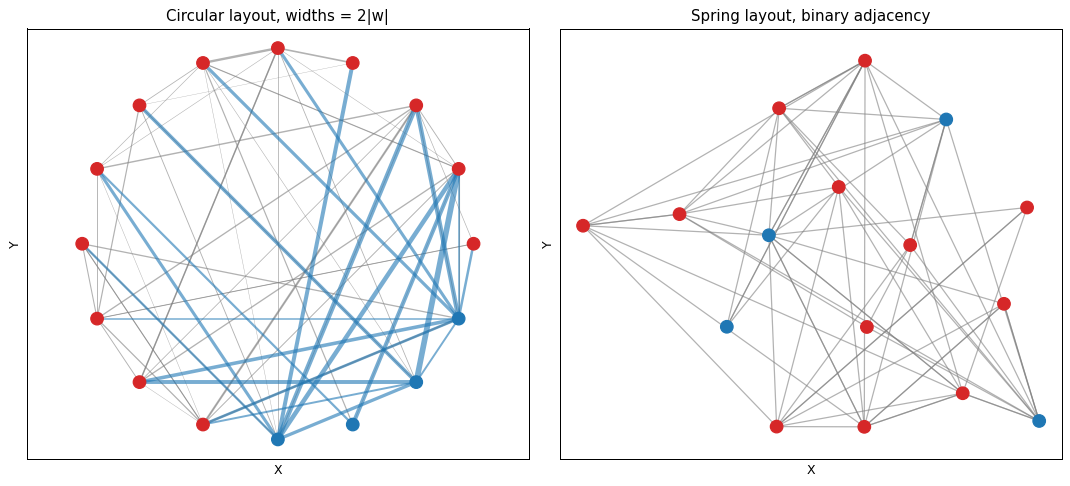

In [3]:
idx = np.r_[0:12, 40:44]                         # 12 E and 4 I neurons
W_small = W[np.ix_(idx, idx)]
node_colors = ["C3"] * 12 + ["C0"] * 4

fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
braintools.visualize.network_topology(W_small, layout="circular", node_colors=node_colors,
                                      edge_widths=2 * np.abs(W_small), ax=ax[0],
                                      title="Circular layout, widths = 2|w|")
np.random.seed(0)
braintools.visualize.network_topology(W_small != 0, layout="spring", node_colors=node_colors, ax=ax[1],
                                      title="Spring layout, binary adjacency")
for a in ax:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

In the weighted graph the inhibitory neurons (blue nodes) send blue, thicker edges. The `'spring'` layout is a basic force-directed scheme with $O(N^2)$ work per iteration, intended for small graphs.

## 4. Correlation Matrices

Pairwise correlations of binned spike counts reveal shared input. Below, 12 neurons in two assemblies: each assembly shares a common, slowly fluctuating input. `correlation_matrix` takes data of shape `(samples, variables)` and computes Pearson, Spearman or Kendall correlations; `mask_diagonal=True` hides the trivial ones on the diagonal.

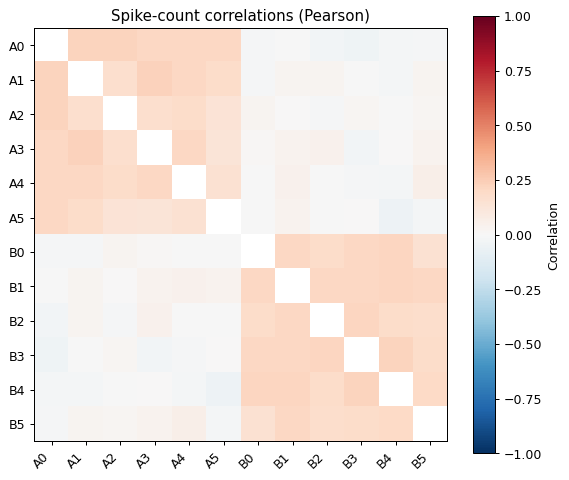

mean correlation within assemblies 0.19, between 0.00


In [4]:
n_bins = 2000
shared = rng.normal(size=(n_bins, 2))
assembly = np.repeat([0, 1], 6)
drive = 1.0 + 0.6 * shared[:, assembly] + 0.8 * rng.normal(size=(n_bins, 12))
counts = rng.poisson(np.maximum(drive, 0) * 2.0)            # spike counts per bin

fig, ax = plt.subplots(figsize=(6.5, 5.5))
braintools.visualize.correlation_matrix(counts, labels=[f"A{i}" for i in range(6)] + [f"B{i}" for i in range(6)],
                                        mask_diagonal=True, show_values=False, ax=ax,
                                        title="Spike-count correlations (Pearson)")
plt.tight_layout(); plt.show()
C = np.corrcoef(counts.T)
print(f"mean correlation within assemblies {C[:6, :6][~np.eye(6, dtype=bool)].mean():.2f}, "
      f"between {C[:6, 6:].mean():.2f}")

## 5. Tuning Curves

`tuning_curve(stimulus, response)` bins the stimulus, plots the mean response per bin with SEM error bars, and can overlay a `'gaussian'` (baseline + Gaussian bump) or cubic `'polynomial'` fit. Three simulated orientation-selective neurons, recorded on 1500 trials with random orientations:

neuron with preference  45.0 deg: fitted peak at  44.5 deg, peak rate 26.6 Hz (true 27)
neuron with preference  90.0 deg: fitted peak at  90.8 deg, peak rate 26.8 Hz (true 27)
neuron with preference 135.0 deg: fitted peak at 135.4 deg, peak rate 27.0 Hz (true 27)


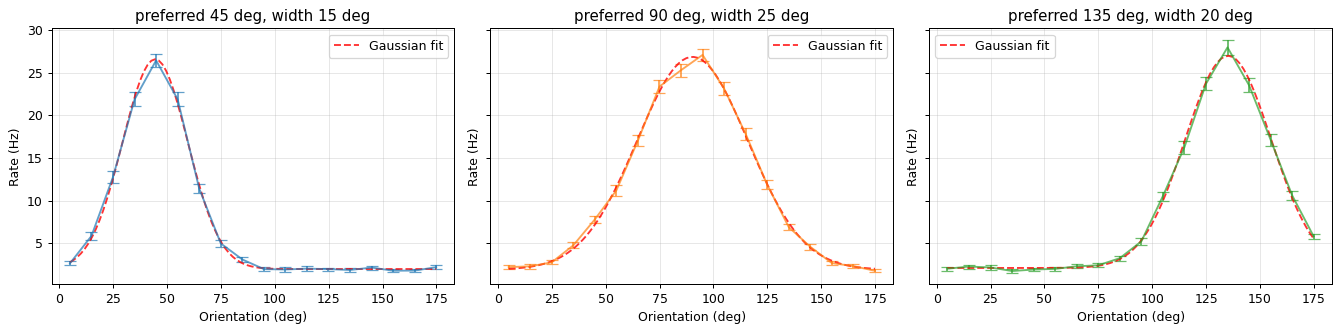

In [5]:
theta = rng.uniform(0, 180, 1500)                       # stimulus orientation in degrees
prefs, widths = [45.0, 90.0, 135.0], [15.0, 25.0, 20.0]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, pref, width, color in zip(ax, prefs, widths, ["C0", "C1", "C2"]):
    rate = 2 + 25 * np.exp(-(theta - pref) ** 2 / (2 * width ** 2))
    response = rng.poisson(rate * 0.5) / 0.5               # spike count in a 500 ms window, in Hz
    braintools.visualize.tuning_curve(theta, response, bins=18, fit_curve="gaussian", color=color, ax=a,
                                      xlabel="Orientation (deg)", ylabel="Rate (Hz)",
                                      title=f"preferred {pref:g} deg, width {width:g} deg")
    x_fit, y_fit = [l for l in a.get_lines() if l.get_label() == "Gaussian fit"][0].get_data()
    print(f"neuron with preference {pref:5.1f} deg: fitted peak at {x_fit[np.argmax(y_fit)]:5.1f} deg, "
          f"peak rate {y_fit.max():.1f} Hz (true 27)")
plt.tight_layout(); plt.show()

The fit starts from the data (peak position, range, amplitude), so it works for stimuli in any units, degrees here. The fitted curve is drawn but its parameters are not returned; for quantitative fits, use `scipy.optimize.curve_fit` directly.

## 6. Phase Portraits

`phase_portrait(x, y)` draws a 2-D trajectory colored by time; with `vector_field=True` and `dx`, `dy` it draws arrows at the points `(x, y)`. The arrows are drawn in data units at their true length, so a vector field usually needs **normalizing** (or scaling by a small time step) before plotting.

The FitzHugh–Nagumo model, $\dot v = v - v^3/3 - w + I$, $\dot w = 0.08\,(v + 0.7 - 0.8\,w)$, with $I = 0.5$ has a limit cycle:

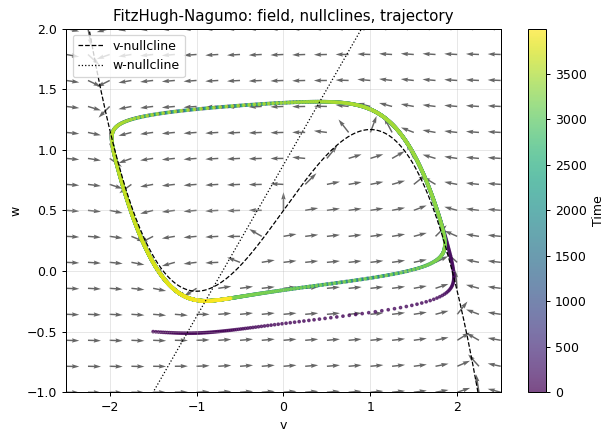

In [6]:
I_ext = 0.5
fv = lambda v, w: v - v ** 3 / 3 - w + I_ext
fw = lambda v, w: 0.08 * (v + 0.7 - 0.8 * w)

dt, n_steps = 0.05, 4000
traj = np.zeros((n_steps, 2)); traj[0] = (-1.5, -0.5)
for k in range(1, n_steps):
    v, w = traj[k - 1]
    traj[k] = traj[k - 1] + dt * np.array([fv(v, w), fw(v, w)])

V, Wg = np.meshgrid(np.linspace(-2.5, 2.5, 21), np.linspace(-1, 2, 15))
dV, dW = fv(V, Wg), fw(V, Wg)
norm = np.hypot(dV, dW)
scale = 0.15 / norm                                      # all arrows 0.15 long

fig, ax = plt.subplots(figsize=(7, 5))
braintools.visualize.phase_portrait(V.ravel(), Wg.ravel(), dx=(dV * scale).ravel(), dy=(dW * scale).ravel(),
                                    trajectory=False, vector_field=True, ax=ax)
braintools.visualize.phase_portrait(traj[:, 0], traj[:, 1], ax=ax, s=4,
                                    title="FitzHugh-Nagumo: field, nullclines, trajectory")
vv = np.linspace(-2.5, 2.5, 200)
ax.plot(vv, vv - vv ** 3 / 3 + I_ext, "k--", lw=1, label="v-nullcline")
ax.plot(vv, (vv + 0.7) / 0.8, "k:", lw=1, label="w-nullcline")
ax.set_xlim(-2.5, 2.5); ax.set_ylim(-1, 2); ax.set_xlabel("v"); ax.set_ylabel("w"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

The trajectory starts at $(-1.5, -0.5)$ and converges onto the limit cycle around the unstable fixed point where the nullclines cross.

## 7. Population Trajectories

The activity of many neurons often evolves in a low-dimensional subspace. `neural_trajectory` plots the columns `dims` of a `(time, features)` array as a 2-D or 3-D curve colored by time, with start and end markers. A typical use is to project population rates onto their principal components first.

Here 80 neurons mix a rotating, decaying 2-D latent signal (as in motor-cortex models of reaching) with noise:

variance explained by the first 3 PCs: [0.574 0.392 0.001]


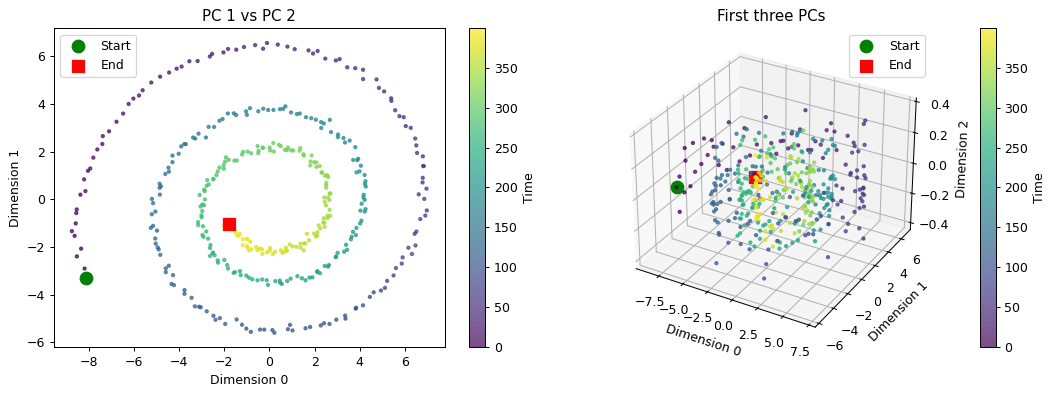

In [7]:
t = np.linspace(0, 1, 400)
latent = np.exp(-1.5 * t)[:, None] * np.c_[np.cos(2 * np.pi * 3 * t), np.sin(2 * np.pi * 3 * t)]
mixing = rng.normal(size=(2, 80))
rates = latent @ mixing + 0.1 * rng.normal(size=(400, 80))

centered = rates - rates.mean(0)
U, S, Vt = np.linalg.svd(centered, full_matrices=False)
pcs = centered @ Vt[:3].T
print("variance explained by the first 3 PCs:", np.round(S[:3] ** 2 / np.sum(S ** 2), 3))

fig = plt.figure(figsize=(12, 4.5))
ax1 = fig.add_subplot(1, 2, 1)
braintools.visualize.neural_trajectory(pcs, dims=(0, 1), ax=ax1, s=6, title="PC 1 vs PC 2")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
braintools.visualize.neural_trajectory(pcs, dims=(0, 1, 2), ax=ax2, s=6, title="First three PCs")
plt.tight_layout(); plt.show()

Two components carry almost all the variance, and in their plane the population state spirals inwards; the third PC holds only noise. The axes are labelled with the column indices (`Dimension 0`, ...), here the principal components.

## Summary

- `connectivity_matrix(W)` expects `W[pre, post]` and centers diverging colormaps at zero by default.
- `network_topology` draws all non-zero edges, negative ones in blue; `edge_widths` and `edge_colors` take an `(N, N)` matrix, one value per edge, or a scalar.
- `correlation_matrix` computes Pearson, Spearman or Kendall correlations of `(samples, variables)` data.
- `tuning_curve` bins the stimulus, plots mean ± SEM and can overlay a Gaussian fit.
- `phase_portrait` arrows are drawn at their true length in data units; normalize the vector field first.
- `neural_trajectory` plots chosen columns of `(time, features)` data, typically principal components, in 2-D or 3-D.